# Practical Session 5 - Parallel Markov chains with multiprocessing and dask

Students (pair):
- [FERHOUN Zineb]([link](https://github.com/zineb-f))
- [AMALADASSE Louise]([link](https://github.com/louiseamaladasse-a11y))

**Useful references for this lab**:

[1] `seaborn`: [official tutorial](https://seaborn.pydata.org/tutorial.html)

[2] `multiprocessing`: [documentation](https://docs.python.org/3/library/multiprocessing.html), [doc2](https://he-arc.github.io/livre-python/multiprocessing/index.html)

[3] `dask`: [documentation](http://numba.pydata.org/) 

## <a name="content">Contents</a>
- [Exercise 1: seaborn, a useful tool for data visualisation](#ex1)
- [Exercise 2: Simulating a discrete-time homogeneous Markov chain](#ex2)
- [Bonus: Parallel computing with Dask](#bonus)
---

In [2]:
%load_ext autoreload
%autoreload 2

## <a name="ex1">Exercise 1: seaborn, a useful tool for data visualisation</a> [(&#8593;)](#content)
 
The `seaborn` package can significantly enhance data and data analysis visualization. See the [tutorial page](https://seaborn.pydata.org/tutorial.html) for examples of effective predefined graphics. An example aimed at visualizing the empirical distributions of 9 realizations of a bivariate Gaussian random vector is reported below.

C:\Users\Zineb\AppData\Local\Temp\ipykernel_88708\1573286285.py:19: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(x=x, y=y, cmap=cmap, shade=True, cut=5, ax=ax)
C:\Users\Zineb\AppData\Local\Temp\ipykernel_88708\1573286285.py:19: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(x=x, y=y, cmap=cmap, shade=True, cut=5, ax=ax)
C:\Users\Zineb\AppData\Local\Temp\ipykernel_88708\1573286285.py:19: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(x=x, y=y, cmap=cmap, shade=True, cut=5, ax=ax)
C:\Users\Zineb\AppData\Local\Temp\ipykernel_88708\1573286285.py:19: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=

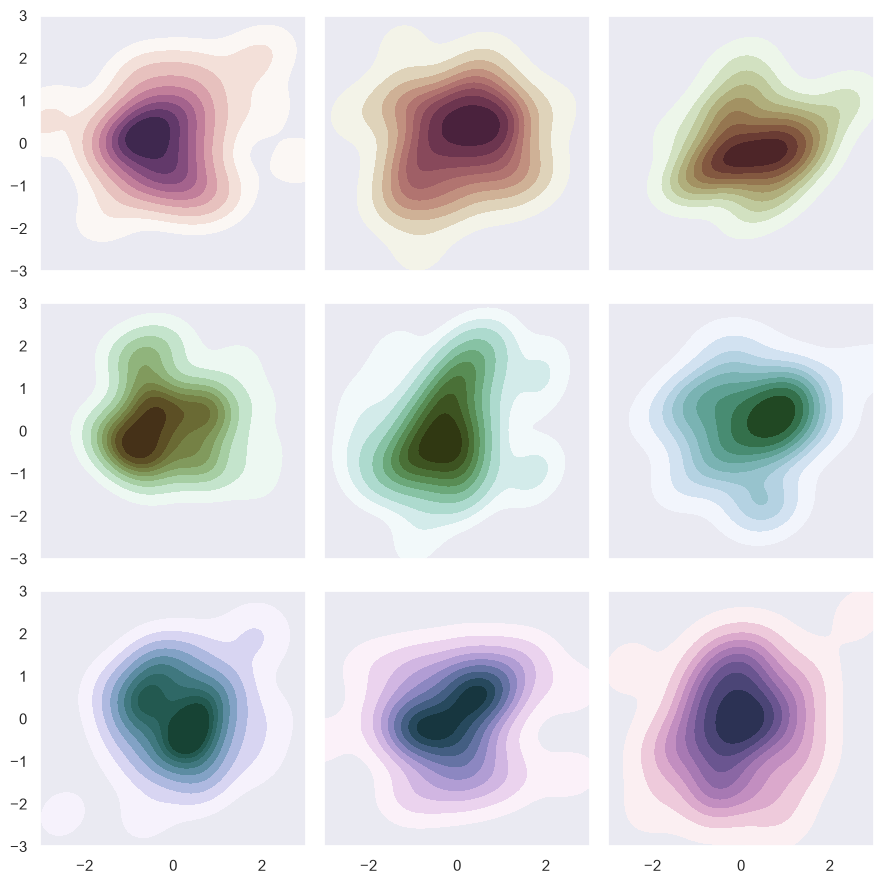

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

sns.set(style="dark")
rng = np.random.default_rng(50)

# Set up the matplotlib figure
f, axes = plt.subplots(3, 3, figsize=(9, 9), sharex=True, sharey=True)

# Rotate the starting point around the cubehelix hue circle
for ax, s in zip(axes.flat, np.linspace(0, 3, 10)):

    # Create a cubehelix colormap to use with kdeplot
    cmap = sns.cubehelix_palette(start=s, light=1, as_cmap=True)

    # Generate and plot a random bivariate dataset
    x, y = rng.normal(size=(2, 50))
    sns.kdeplot(x=x, y=y, cmap=cmap, shade=True, cut=5, ax=ax)
    ax.set(xlim=(-3, 3), ylim=(-3, 3))

f.tight_layout()

1. Comment on the lines of codes related to the `seaborn` library to make their role explicit. More specifically comment on the KDE method.

**Answer:**

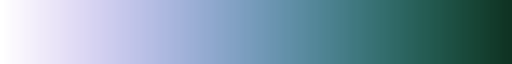

In [4]:
sns.cubehelix_palette(start=2, light=1, as_cmap=True)


- sns.set permet juste d'indiquer le thème souhaité
- sns.cubehelix_palette() : génère une palette de couleurs (Colormap Matplotlib) dont la luminosité diminue (ou augmente) de manière linéaire. L'avantage est que les informations seront préservées en cas d’impression en noir et blanc ou de visualisation par une personne daltonienne.Du fait de la linéarité, cela garantit également qu'une couleur deux fois plus claire indique une densité deux fois plus faible. 
  - dans notre cas, sur chaque graphe, la couleur de départ s varie
- On utilise ensuite cette palette dans sns.kdeplot(). Cette commande permet de visualiser la distribution de probabilité continue d'une ou deux variables. C'est l'alternative lissée de l'histogramme : au lieu de découper les données en blocs (bins), il trace une courbe de densité fluide.
  - sur cette ligne : sns.kdeplot(x=x, y=y, cmap=cmap, shade=True, cut=5, ax=ax) trace le KDE 2d

2. For one of the realizations, take a look at the documentation of [`sns.jointplot`](https://seaborn.pydata.org/examples/joint_kde.html) to display both the 2-D empirical distribution of the data, and 1D histograms of their distribution along each axis. 

**Answer:**

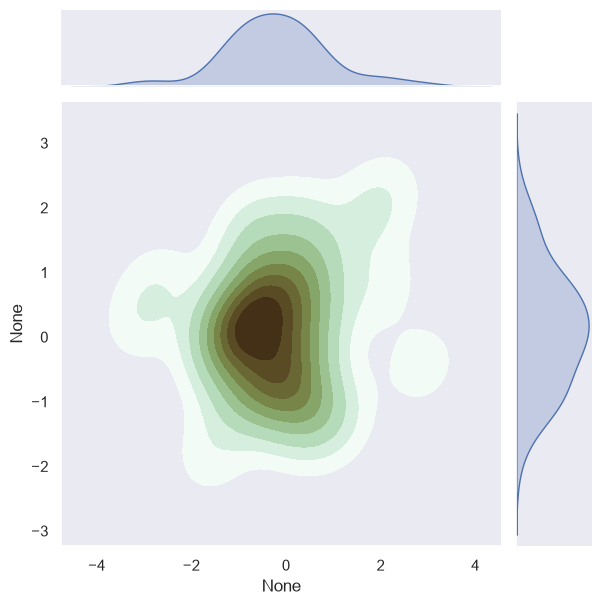

In [5]:
import numpy as np
import seaborn as sns

sns.set_theme(style="dark")
rng = np.random.default_rng(50)

cmap = sns.cubehelix_palette(start=1, light=1, as_cmap=True)

# On teste avec une réalisation
x, y = rng.normal(size=(2, 50))

g = sns.jointplot(
    x=x,
    y=y,
    kind="kde", # Pour la distribution 2D en KDE
    cmap=cmap,
    fill=True
)

<Axes: xlabel='Count'>

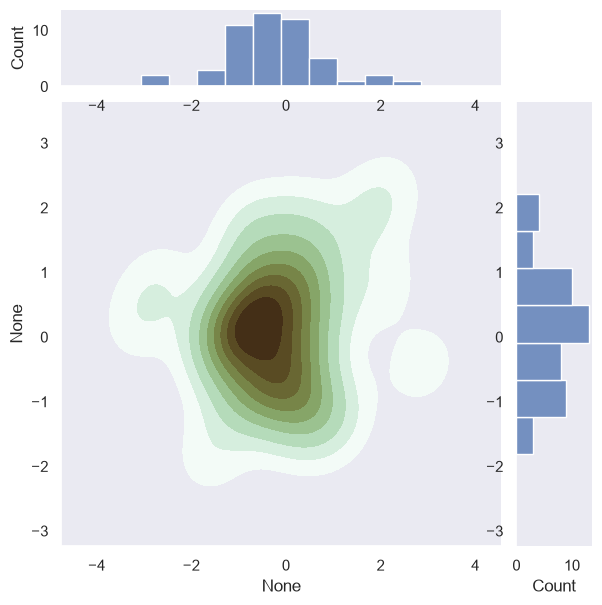

In [6]:
g = sns.jointplot(
    x=x,
    y=y,
    kind="kde",
    fill=True,
    cmap=cmap
)

g.ax_marg_x.clear()
g.ax_marg_y.clear()

sns.histplot(x=x, ax=g.ax_marg_x)
sns.histplot(y=y, ax=g.ax_marg_y)

## <a name="ex2">Exercise 2: Simulating a discrete-time homogeneous Markov chain.</a> [(&#8593;)](#content)


Let ${(X_n)}_{n\geq 0}$ be a discrete-time homogeneous Markov chain with values over a finite ensemble $E=\{x_1,\dots,x_N\}$ identified to $\{1,\dots,N\}$. Consider $\boldsymbol{\rho} \in \Delta_N$, where $\Delta_N = \{\mathbf{x}\in\mathbb{R}^N \mid x_n \geq 0 \, \forall n \in \{1,\dotsc,N\} \text{ and } \sum_n x_n = 1 \}$ is the unit simplex in $\mathbb{R}^N$.

In the following, we consider the initial state of the chain $X_0$, following the discrete probability distribution:

$$
    \mathbb{P}(X_0 = k) = \rho_k, \qquad k \in \{1, \dots,  N\}.
$$
  
Let $\mathbf{A} = [a_{i,j}]_{i,j} \in \mathbb{R}^{N \times N}$ be the transition matrix of the chain, i.e.,

\begin{align*}
    &a_{i,j} = \mathbb{P}(X_{n+1} = j \mid X_{n} = i) \geq 0, \, \forall n \geq 0, \\
    &(\forall i \in \{1, \dotsc, N\}), \quad \sum_{j=1}^N a_{i,j} = 1.
\end{align*}
 
The chain is said to be homogeneous in that $\mathbf{A}$ does not depend from the time index $n$. Let $\tilde{a}_n$ represent the $n$th row of $\mathbf{A}$. 

The trajectory of the chain can be simulated as follows:

>- Draw the discrete random variable $X_0$ with distribution $\boldsymbol{\rho}$;
>
>- For $q = 0$ to $n_{\text{iter}}-1$
>    - Draw the discrete random variable $X_{q+1}$ with distribution $\tilde{a}_{X_{q}}$;
>    
>- Return ${(X_q)}_{0 \leq q \leq n_{\text{iter}}}$.


<!-- If $X_n = k$, we know that $T$, the life time of the chain in the state $k$ obeys a geometric distribution with parameter $a_{kk}$. We also know that the probability of transition from k to $\ell\neq k$ is given by:

$$
    \mathbb{P}(X_{n+1}=\ell | X_n=k, \ell\neq k) = \frac{a_{k\ell}}{1-a_{kk}}.
$$

 ### One possible algorithm to simulate a Markov chain is therefore:

    a. generate the initial state $X_0$ according to the discrete law $\{\rho_1,\dots,\rho_N\}$.

    b. at instant $n$, knowing that $X_n=k$,

    i) determine the life time $T$ in state $X_n=k$ by simulating a geometrical variable with parameter $a_{kk}$. As a consequence $X_n = \dots = X_{n+T} = k$. When $T=0$, we simply still have $X_n=k$.

    ii) determine next transition instant $n+T$, and determine the next state by using the probabilities of transition. -->

1. Implement the above algorithm in a function `X = markov(rho,A,nmax,rng)` with:
     - `rho`: law of the initial state (nonnegative vector of size $N$, summing to 1),
     - `A`: transition matrix (of size $N\times N$),
     - `nmax`: number of time steps,
     - `rng`: random number generator
     - `X`: trajectory of the chain.
     
In particular, check the input parameters `A` and `rho` make sense by adding appropriate assertions (or raising exceptions).

> Hint: the function `np.random.choice` can be useful to draw discrete random variables.

**Answer:**

In [5]:
from markov import markov

# Test
rng = np.random.default_rng(50)

rho = [0.5, 0.5, 0.0]
A = [[0.7, 0.2, 0.1], [0.1, 0.8, 0.1], [0.3, 0.3, 0.4]]

rng = np.random.default_rng(42)
trajectoire = markov(rho, A, nmax=10, rng=rng)
print(f"Trajectoire : {trajectoire}")

Trajectoire : [1 1 1 1 0 2 2 2 0 0 0]


2. Set the random number generator to a known state. Make a few simulations using simple transition matrices (*i.e.*, taking any nonnegative matrix $A=(a_{i,j})$ such that its lines sum to 1) and display the trajectory of the chains.

**Answer:**

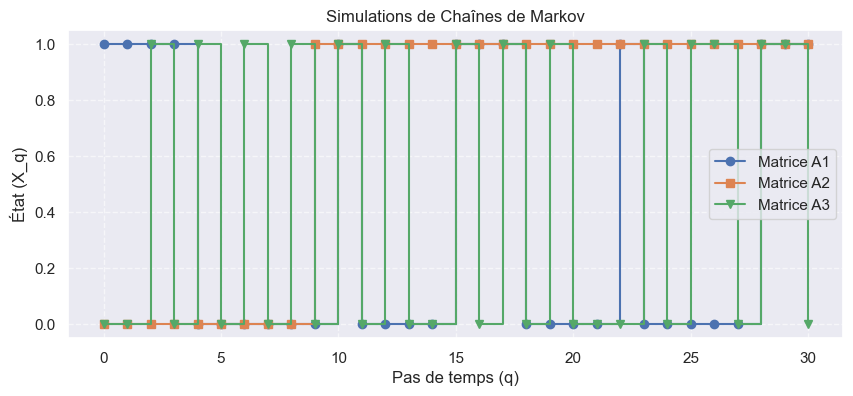

In [6]:
import matplotlib.pyplot as plt

rng = np.random.default_rng(50)

nmax = 30
rho = np.array([0.5, 0.5])  # 2 états : 0 et 1

# Matrices de transition
A1 = np.array([[0.7, 0.3], [0.4, 0.6]])
A2 = np.array([[0.8, 0.2], [0.0, 1.0]])
A3 = np.array([[0.5,0.5], [0.5,0.5]])

X1 = markov(rho, A1, nmax, rng)
X2 = markov(rho, A2, nmax, rng)
X3 = markov(rho, A3, nmax, rng)

plt.figure(figsize=(10, 4))
plt.plot(X1, label="Matrice A1", drawstyle="steps-post", marker="o")
plt.plot(X2, label="Matrice A2", drawstyle="steps-post", marker="s")
plt.plot(X3, label="Matrice A3", drawstyle="steps-post", marker="v")

plt.xlabel("Pas de temps (q)")
plt.ylabel("État (X_q)")
plt.title("Simulations de Chaînes de Markov")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.show()

3. Explore the potential of the [`multiprocessing` package](https://docs.python.org/3/library/multiprocessing.html) to simulate several Markov chains in parallel.

> Hint: the `mutiprocessing.Pool.starmap` or `mutiprocessing.Pool.starmap_async` methods could be useful.

**Answer:**

In [ ]:
import multiprocessing as mp
import time
import numpy as np
from markov import markov

# Paramètres
N_SIMUS = 50
nmax = 50000
rho = np.array([0.5, 0.5])
A = np.array([[0.7, 0.3], [0.4, 0.6]])

# Préparation des arguments pour les 50 simulations
ss = np.random.SeedSequence(42)
rngs = [np.random.default_rng(seed) for seed in ss.spawn(N_SIMUS)]
tasks = [(rho, A, nmax, rng) for rng in rngs]

# Version séquentiel
t0 = time.perf_counter()
res_seq = []
for task in tasks:
    res_seq.append(markov(*task))
t_seq = time.perf_counter() - t0
print(f"Séquentiel : {t_seq:.2f} s")

# Version parallèle (multi-processing)
if __name__ == "__main__": # pas nécessaire comme notebook mais on le laisse par prévention
    t0 = time.perf_counter()
    with mp.Pool() as pool:
        res_par = pool.starmap(markov, tasks)
    t_par = time.perf_counter() - t0
    print(f"Multiprocessing : {t_par:.2f} s")

    print(f"Gain de vitesse : x{t_seq / t_par:.2f}")

Séquentiel : 45.32 s
Multiprocessing : 10.13 s
Gain de vitesse : x4.47


4. [Bonus] Generate Markov chains in parallel with the [`dask`](https://docs.dask.org/en/latest/futures.html) library, which offers more general parallelization functionalities (with, for instance, the use of [`Futures`](https://docs.dask.org/en/stable/futures.html), see tutorial [here](https://tutorial.dask.org/05_futures.html)). A useful example is provided [here](https://stackoverflow.com/questions/41471248/how-to-efficiently-submit-tasks-with-large-arguments-in-dask-distributed). Note that `dask` is much more versatile and powerful than `multiprocessing`, and can be useful to scale algorithms over multiple cores and/or computing nodes.

**Answer:**

## <a name="bonus">Bonus: Parallel computing with Dask</a> [(&#8593;)](#content)

1. Take a look at the [`dask.array` documentation](https://docs.dask.org/en/stable/array-best-practices.html) and the associate [tutorial](https://tutorial.dask.org/02_array.html). Apply some of the functions introduced herein and in the [documentation](https://docs.dask.org/en/stable/array-best-practices.html) to parallelize the computation of the total variation investigated during session 2. Note that you can combine `dask` and `numba` to obtain an overall more efficient implementation. Note that timing can be worse than Numpy (`dask.array` is more specifically interesting when the data do no fit in memory).

2. Take a look at the [`dask.delayed` tutorial](https://tutorial.dask.org/03_dask.delayed.html), and go through some of the examples provided. [Best practices with the `dask.delayed` interface](https://docs.dask.org/en/stable/delayed-best-practices.html) are summarized in the documentation.

> **Remark**: an alternative to Dask: the [Ray](https://docs.ray.io/en/latest/) library.

**Answer:**

In [ ]:
# your code